# MakeMore

In [9]:
names = open("Data/names.txt", "r").read().splitlines()

In [26]:
b = {}
for name in names:
    chs = ["<S>"] + list(name) + ["<E>"]
    for tup in zip(chs, chs[1:]):
        b[tup] = b.get(tup, 0) + 1

sorted(b.items(), key=lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

### Bigram count

In [27]:
import torch

In [51]:
N = torch.zeros(27, 27, dtype=torch.int32)
chars = sorted(list(set("".join(names))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {s: i for i, s in stoi.items()}


In [57]:
for name in names:
    chs = ["."] + list(name) + ["."]
    for ch1, ch2 in zip(chs, chs[1: ]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

In [59]:
N.shape

torch.Size([27, 27])

### Bigram Count Plot

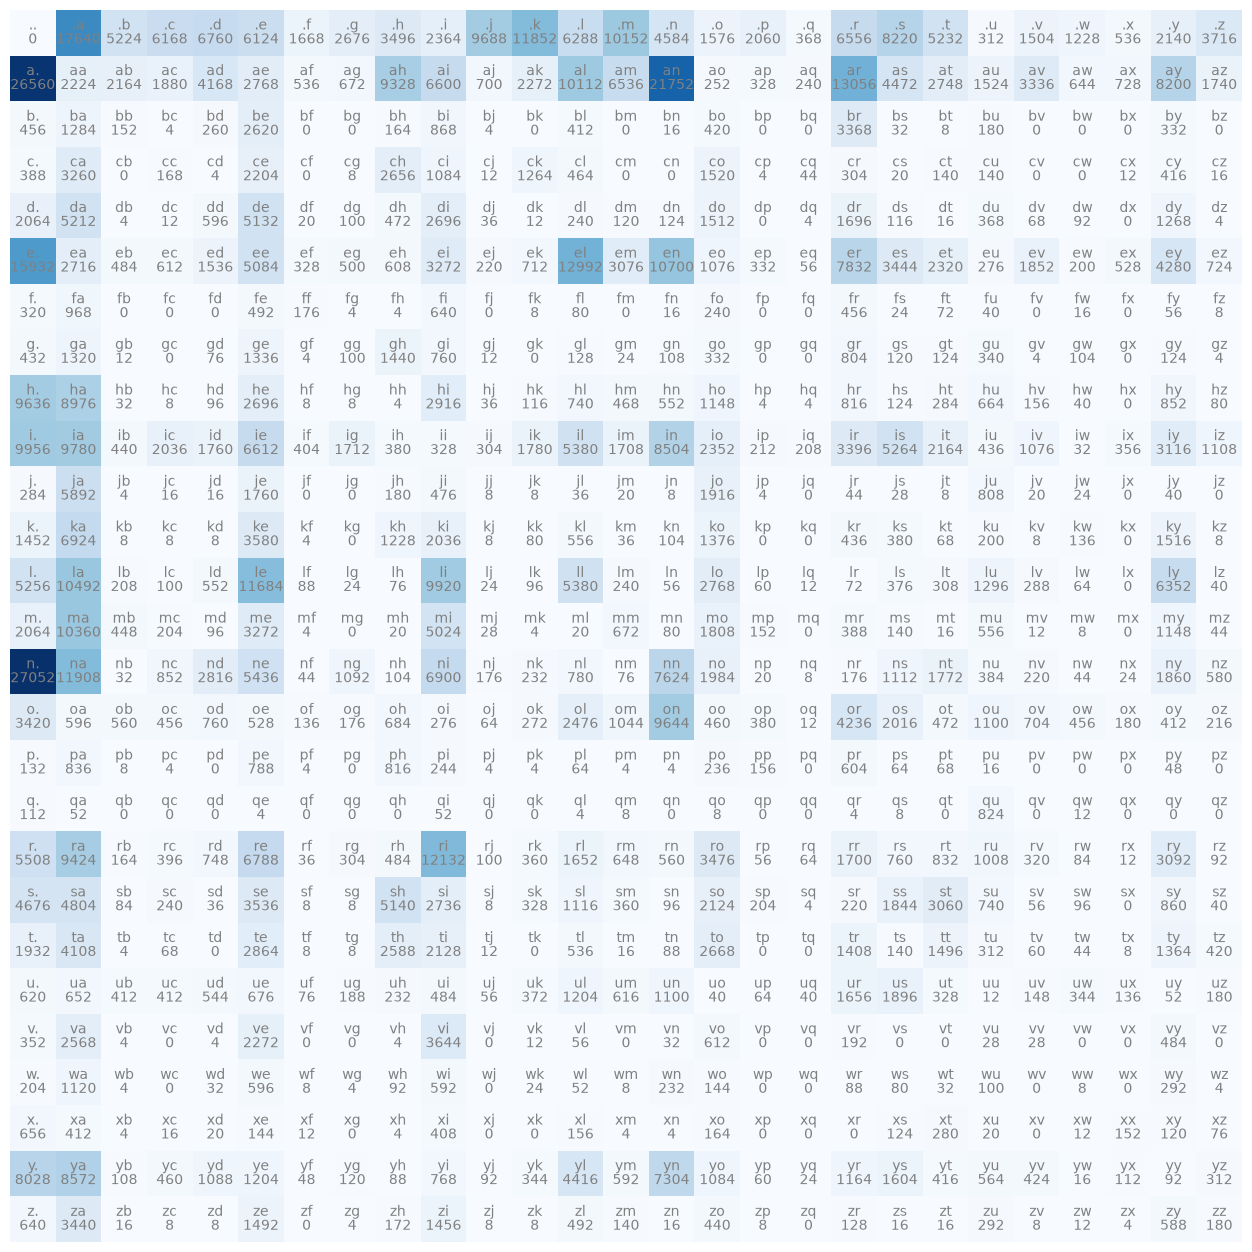

In [60]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

In [61]:
N[0]

tensor([    0, 17640,  5224,  6168,  6760,  6124,  1668,  2676,  3496,  2364,
         9688, 11852,  6288, 10152,  4584,  1576,  2060,   368,  6556,  8220,
         5232,   312,  1504,  1228,   536,  2140,  3716], dtype=torch.int32)

### Getting Probablity distribution

#### Example of Multinomial

In [79]:
g = torch.Generator().manual_seed(2147483647)
r = torch.rand(3, generator=g)
r = r/r.sum()
r

tensor([0.6064, 0.3033, 0.0903])

In [80]:
torch.multinomial(r, 20, replacement=True, generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1])

In [94]:
p = N[0].float()
p  = p/p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [99]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]

'c'

In [117]:
g = torch.Generator().manual_seed(2147483647)

for i in range (5):
    ix = 0
    out = []
    while True:
        p = N[ix].float()
        p = p/p.sum()
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break

    print("".join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.


### Broadcasting

In [113]:
P = (N+1).float()
P /= P.sum(1, keepdims=True)
P.shape

torch.Size([27, 27])

In [118]:
P[0]

tensor([7.8028e-06, 1.3765e-01, 4.0770e-02, 4.8136e-02, 5.2755e-02, 4.7792e-02,
        1.3023e-02, 2.0888e-02, 2.7286e-02, 1.8454e-02, 7.5601e-02, 9.2487e-02,
        4.9072e-02, 7.9222e-02, 3.5776e-02, 1.2305e-02, 1.6082e-02, 2.8792e-03,
        5.1163e-02, 6.4147e-02, 4.0832e-02, 2.4423e-03, 1.1743e-02, 9.5897e-03,
        4.1901e-03, 1.6706e-02, 2.9003e-02])

In [116]:
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  
  out = []
  ix = 0
  while True:
    p = P[ix]
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
